# IMPORT

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
import seaborn as sns
from pathlib import Path
import csv
import os
from collections import Counter

# DEFINE FOLDERS

In [2]:
BASE_FOLDER = Path("../data")

DATASET_INPUT_FOLDER = BASE_FOLDER / "01_clean" / "datasets"
MISSING_STATION_DATA_FOLDER = BASE_FOLDER / "01_clean" / "missing_station_data"
MODEL_RESULTS_FOLDER = BASE_FOLDER / "04_models" / "evaluation"
MODEL_STATS_FOLDER = BASE_FOLDER / "06_statistics" / "model_statistics"
MODEL_STATS_PLOT_FOLDER = BASE_FOLDER / "05_visualization" / "model_stats"
PLOT_FOLDER = BASE_FOLDER / "05_visualization" / "plots"
PIPELINE_PLOT_FOLDER = BASE_FOLDER / "05_visualization" / "pipeline"
STATISTICS_DATA_FOLDER = BASE_FOLDER / "06_statistics" / "aggregated"
STATION_SPLIT_WELNESS_FOLDER = BASE_FOLDER / "05_visualization" / "per_station"
PIPELINE_CSV_FOLDER = BASE_FOLDER / "06_statistics" / "pipeline"

folders = [DATASET_INPUT_FOLDER, 
            PLOT_FOLDER, 
            MISSING_STATION_DATA_FOLDER, 
            STATISTICS_DATA_FOLDER, 
            STATION_SPLIT_WELNESS_FOLDER, 
            MODEL_RESULTS_FOLDER,
            MODEL_STATS_FOLDER,
            MODEL_STATS_PLOT_FOLDER,
            PIPELINE_CSV_FOLDER,
            PIPELINE_PLOT_FOLDER
        ]
for folder in folders:
    folder.mkdir(parents=True, exist_ok=True)

# LOAD DATA

In [3]:
df = pd.read_csv(f"{DATASET_INPUT_FOLDER}/final_clean_split_data.csv")
display(df.info())

display(df.head(5))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6710838 entries, 0 to 6710837
Data columns (total 20 columns):
 #   Column             Dtype  
---  ------             -----  
 0   timestamp          object 
 1   station_code       int64  
 2   latitude           float64
 3   longitude          float64
 4   capacity           float64
 5   total_bikes_now    float64
 6   total_bikes_taken  float64
 7   temperature        float64
 8   wind_speed         float64
 9   wind_direction     float64
 10  weather_code       float64
 11  is_day             float64
 12  hour               int64  
 13  day_of_week        int64  
 14  is_weekend         int64  
 15  sin_hour           float64
 16  cos_hour           float64
 17  total_bikes_lag1   float64
 18  total_bikes_lag2   float64
 19  split              int64  
dtypes: float64(14), int64(5), object(1)
memory usage: 1024.0+ MB


None

,timestamp,station_code,latitude,longitude,capacity,total_bikes_now,total_bikes_taken,temperature,wind_speed,wind_direction,weather_code,is_day,hour,day_of_week,is_weekend,sin_hour,cos_hour,total_bikes_lag1,total_bikes_lag2,split
0,2025-11-04 04:30:00,1001,48.857059,2.341798,17.0,2.0,15.0,9.0,8.0,207.0,3.0,0.0,4,1,0,0.866025,0.500000,2.0,2.0,0
1,2025-11-04 04:45:00,1001,48.857059,2.341798,17.0,2.0,15.0,9.1,8.2,203.0,3.0,0.0,4,1,0,0.866025,0.500000,2.0,2.0,0
2,2025-11-04 05:00:00,1001,48.857059,2.341798,17.0,2.0,15.0,9.1,8.2,203.0,3.0,0.0,5,1,0,0.965926,0.258819,2.0,2.0,0
3,2025-11-04 05:15:00,1001,48.857059,2.341798,17.0,2.0,15.0,9.1,8.1,201.0,3.0,0.0,5,1,0,0.965926,0.258819,2.0,2.0,0
4,2025-11-04 05:30:00,1001,48.857059,2.341798,17.0,2.0,15.0,9.1,8.4,200.0,3.0,0.0,5,1,0,0.965926,0.258819,2.0,2.0,0


# CONSTANTS

In [26]:
EXPECTED_MINUTES = [0, 15, 30, 45]
EXPECTED_SLOTS_PER_DAY = 24 * 4  # 96

# MISSING DATA COMPUTATION PER STATION

In [27]:
def compute_missing_data(station_id, df):
    df_s = df[df["station_code"] == station_id].copy()

    # Ensure timestamp is datetime
    df_s["timestamp"] = pd.to_datetime(df_s["timestamp"])
    df_s["date"] = df_s["timestamp"].dt.date
    df_s["hour"] = df_s["timestamp"].dt.hour
    df_s["minute"] = df_s["timestamp"].dt.minute

    records = []

    for date, day_df in df_s.groupby("date"):
        # Count how many rows exist for each (hour, minute)
        counts = Counter(zip(day_df["hour"], day_df["minute"]))

        for hour in range(24):
            for minute in EXPECTED_MINUTES:
                records.append({
                    "station_code": station_id,
                    "date": date,
                    "hour": hour,
                    "minute": minute,
                    "present": counts.get((hour, minute), 0)  # number of rows at that time
                })

    return pd.DataFrame(records)

# COMPUTE MISSING DATA FOR ALL STATIONS

In [28]:
all_missing = []

for station_id in df["station_code"].unique():
    all_missing.append(compute_missing_data(station_id, df))

missing_df = pd.concat(all_missing, ignore_index=True)
display(missing_df.head())
missing_df.describe()

,station_code,date,hour,minute,present
0,1001,2025-11-04,0,0,0
1,1001,2025-11-04,0,15,0
2,1001,2025-11-04,0,30,0
3,1001,2025-11-04,0,45,0
4,1001,2025-11-04,1,0,0


,station_code,hour,minute,present
count,6.792000e+06,6.792000e+06,6.792000e+06,6.792000e+06
mean,1.906877e+04,1.150000e+01,2.250000e+01,9.866558e-01
std,1.240912e+04,6.922187e+00,1.677051e+01,1.147439e-01
min,1.001000e+03,0.000000e+00,0.000000e+00,0.000000e+00
25%,1.103600e+04,5.750000e+00,1.125000e+01,1.000000e+00
50%,1.700300e+04,1.150000e+01,2.250000e+01,1.000000e+00
75%,2.240200e+04,1.725000e+01,3.375000e+01,1.000000e+00
max,9.200800e+04,2.300000e+01,4.500000e+01,1.000000e+00


# SAVE IT

In [29]:
missing_df.to_csv(f"{MISSING_STATION_DATA_FOLDER}/missing_data_detailed.csv", index=False)
print(f"Saved: {MISSING_STATION_DATA_FOLDER}/missing_data_detailed.csv")

Saved: ..\data\01_clean\missing_station_data/missing_data_detailed.csv


# STATION SUMMARY

In [30]:
station_summary = (
    missing_df
    .groupby("station_code")["present"]
    .agg(
        total_slots="count",
        present_slots="sum"
    )
)

station_summary["missing_slots"] = (
    station_summary["total_slots"] - station_summary["present_slots"]
)

station_summary["missing_ratio"] = (
    station_summary["missing_slots"] / station_summary["total_slots"]
)

display(station_summary.sort_values("missing_ratio", ascending=False).head())
display(station_summary.describe())

,total_slots,present_slots,missing_slots,missing_ratio
station_code,,,,
3012,4800,4734,66,0.01375
4104,4800,4734,66,0.01375
2017,4800,4734,66,0.01375
2022,4800,4734,66,0.01375
2110,4800,4734,66,0.01375


,total_slots,present_slots,missing_slots,missing_ratio
count,1415.0,1415.000000,1415.000000,1415.000000
mean,4800.0,4735.947703,64.052297,0.013344
std,0.0,0.319266,0.319266,0.000067
min,4800.0,4734.000000,64.000000,0.013333
25%,4800.0,4736.000000,64.000000,0.013333
50%,4800.0,4736.000000,64.000000,0.013333
75%,4800.0,4736.000000,64.000000,0.013333
max,4800.0,4736.000000,66.000000,0.013750


# SAVE IT

In [31]:
station_summary.to_csv(f"{MISSING_STATION_DATA_FOLDER}/missing_data_by_station.csv")
print(f"Saved: {MISSING_STATION_DATA_FOLDER}/missing_data_by_station.csv")

Saved: ..\data\01_clean\missing_station_data/missing_data_by_station.csv


# MISSING DATA BY TIMESTAMP

In [32]:
time_summary = (
    missing_df
    .groupby(["hour", "minute"])["present"]
    .mean()
    .reset_index()
)

time_summary["missing_ratio"] = 1 - time_summary["present"]
time_summary.sort_values("missing_ratio", ascending=False).head()

,hour,minute,present,missing_ratio
0,0,0,0.98,0.02
61,15,15,0.98,0.02
70,17,30,0.98,0.02
69,17,15,0.98,0.02
68,17,0,0.98,0.02


# SAVE IT

In [33]:
time_summary.to_csv(f"{MISSING_STATION_DATA_FOLDER}/missing_data_by_timestamp.csv", index=False)
print(f"Saved: {MISSING_STATION_DATA_FOLDER}/missing_data_by_timestamp.csv")

Saved: ..\data\01_clean\missing_station_data/missing_data_by_timestamp.csv


# MISSING COMPLETE DAYS

In [34]:
daily_summary = (
    missing_df
    .groupby(["station_code", "date"])["present"]
    .sum()
    .reset_index()
)

daily_summary["complete_day_missing"] = (daily_summary["present"] == 0)
daily_summary[daily_summary["complete_day_missing"]].head()

,station_code,date,present,complete_day_missing


# SAVE IT

In [35]:
daily_summary.to_csv(f"{MISSING_STATION_DATA_FOLDER}/missing_data_by_day.csv", index=False)
print(f"Saved: {MISSING_STATION_DATA_FOLDER}/missing_data_by_day.csv")

Saved: ..\data\01_clean\missing_station_data/missing_data_by_day.csv


# DUPLICATES IN THE DATA

In [36]:
# Check duplicates: same station, same timestamp
duplicates = df[df.duplicated(subset=["station_code", "timestamp"], keep=False)]
print(f"Number of duplicate rows: {duplicates.shape[0]}")

# If you want to see which stations have duplicates
dup_counts = duplicates["station_code"].value_counts().sort_values(ascending=False)
print(dup_counts)


Number of duplicate rows: 0
Series([], Name: count, dtype: int64)


# HISTOGRAM OF ROWS

In [37]:
df_counts = df["station_code"].value_counts().reset_index()
df_counts.columns = ["station_code", "count"]
print(df_counts)

      station_code  count
0             1001   4736
1            21115   4736
2            21014   4736
3            21013   4736
4            21011   4736
...            ...    ...
1412          9012   4734
1413          2003   4734
1414          9101   4734
1415          3010   4734
1416          1119   4734

[1417 rows x 2 columns]


count
4734      37
4736    1380
Name: count, dtype: int64


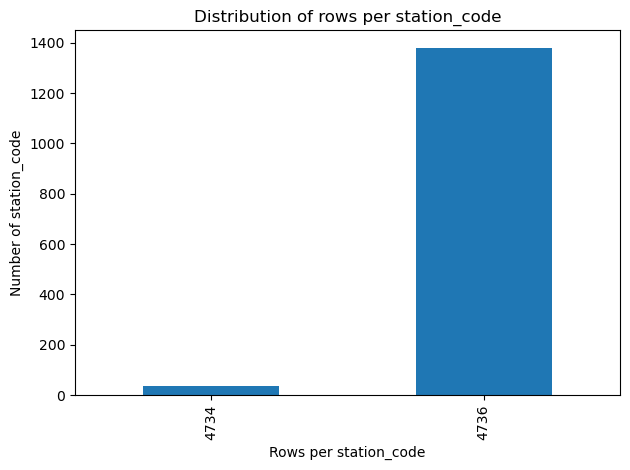

In [38]:
counts = df["station_code"].value_counts()   # index=station_code, value=#rows
count_distribution = counts.value_counts().sort_index()
print(f"{count_distribution}")
count_distribution.plot(kind="bar")
plt.xlabel("Rows per station_code")
plt.ylabel("Number of station_code")
plt.title("Distribution of rows per station_code")
plt.tight_layout()
plt.show()

# STATISTICS FOR EACH STATION

In [39]:
print(f"{df.columns}")
print(df.isna().sum().sort_values(ascending=False))

Index(['timestamp', 'station_code', 'latitude', 'longitude', 'capacity',
       'total_bikes_now', 'total_bikes_taken', 'temperature', 'wind_speed',
       'wind_direction', 'weather_code', 'is_day', 'hour', 'day_of_week',
       'is_weekend', 'sin_hour', 'cos_hour', 'total_bikes_lag1',
       'total_bikes_lag2', 'split'],
      dtype='object')
timestamp            0
station_code         0
total_bikes_lag2     0
total_bikes_lag1     0
cos_hour             0
sin_hour             0
is_weekend           0
day_of_week          0
hour                 0
is_day               0
weather_code         0
wind_direction       0
wind_speed           0
temperature          0
total_bikes_taken    0
total_bikes_now      0
capacity             0
longitude            0
latitude             0
split                0
dtype: int64


In [40]:
excluded_cols = ["station_code", "latitude", "longitude", "timestamp", "wind_direction", "hour", "day_of_week", "is_weekend", "sin_hour", "cos_hour"]
features = [c for c in df.columns if c not in excluded_cols]

station_stats = (
    df.groupby("station_code")[features]
      .agg(["min", "max", "mean", "median"])
)

station_stats.columns = [
    f"{feature}_{stat}" for feature, stat in station_stats.columns
]

station_stats = station_stats.reset_index()

nan_counts = station_stats.isna().sum()

inf_counts = np.isinf(station_stats.select_dtypes(include=[np.number])).sum()

problem_counts = (
    pd.DataFrame({
        "nan": nan_counts,
        "inf": inf_counts
    })
    .fillna(0)
    .astype(int)
    .sort_values(by=["nan", "inf"], ascending=False)
)

print(problem_counts)

                          nan  inf
station_code                0    0
capacity_min                0    0
capacity_max                0    0
capacity_mean               0    0
capacity_median             0    0
total_bikes_now_min         0    0
total_bikes_now_max         0    0
total_bikes_now_mean        0    0
total_bikes_now_median      0    0
total_bikes_taken_min       0    0
total_bikes_taken_max       0    0
total_bikes_taken_mean      0    0
total_bikes_taken_median    0    0
temperature_min             0    0
temperature_max             0    0
temperature_mean            0    0
temperature_median          0    0
wind_speed_min              0    0
wind_speed_max              0    0
wind_speed_mean             0    0
wind_speed_median           0    0
weather_code_min            0    0
weather_code_max            0    0
weather_code_mean           0    0
weather_code_median         0    0
is_day_min                  0    0
is_day_max                  0    0
is_day_mean         

# SAVE IT

In [41]:
station_stats.to_csv(f"{STATISTICS_DATA_FOLDER}/station_statistics.csv", index=False)
print(f"Saved: {STATISTICS_DATA_FOLDER}/station_statistics.csv")

Saved: ..\data\06_statistics\aggregated/station_statistics.csv


# CHECK SPLIT WELNESS PER STATION

In [42]:
# Count rows per station per split
split_counts = (
    df.groupby(["station_code", "split"])
      .size()
      .unstack(fill_value=0)
      .rename(columns={
          0: "train_rows",
          1: "val_rows",
          2: "test_rows"
      })
      .reset_index()
)

display(split_counts.head())

split,station_code,train_rows,val_rows,test_rows
0,1001,3315,710,711
1,1002,3315,710,711
2,1006,3313,710,711
3,1007,3313,710,711
4,1008,3315,710,711


# ADD THE PERCENTAGES AS WELL

In [43]:
# Total rows per station
split_counts["total_rows"] = (
    split_counts["train_rows"]
    + split_counts["val_rows"]
    + split_counts["test_rows"]
)

# Percentages
split_counts["train_pct"] = split_counts["train_rows"] / split_counts["total_rows"] * 100
split_counts["val_pct"]   = split_counts["val_rows"]   / split_counts["total_rows"] * 100
split_counts["test_pct"]  = split_counts["test_rows"]  / split_counts["total_rows"] * 100

display(split_counts.head())

split,station_code,train_rows,val_rows,test_rows,total_rows,train_pct,val_pct,test_pct
0,1001,3315,710,711,4736,69.995777,14.991554,15.012669
1,1002,3315,710,711,4736,69.995777,14.991554,15.012669
2,1006,3313,710,711,4734,69.983101,14.997888,15.019011
3,1007,3313,710,711,4734,69.983101,14.997888,15.019011
4,1008,3315,710,711,4736,69.995777,14.991554,15.012669


# CHECK IF IT CORRESPONDS

In [45]:
# Reference percentages
ref = split_counts.loc[0, ["train_pct", "val_pct", "test_pct"]]

# Absolute percentage difference
split_counts["train_pct_diff"] = split_counts["train_pct"] - ref["train_pct"]
split_counts["val_pct_diff"]   = split_counts["val_pct"]   - ref["val_pct"]
split_counts["test_pct_diff"]  = split_counts["test_pct"]  - ref["test_pct"]

# Are they effectively identical? (tolerance = 0.1%)
tol = 0.1
split_counts["same_pct_as_ref"] = (
    (split_counts["train_pct_diff"].abs() < tol) &
    (split_counts["val_pct_diff"].abs() < tol) &
    (split_counts["test_pct_diff"].abs() < tol)
)


print(f"Stations with percentage mismatch: ")
display((split_counts["same_pct_as_ref"] == False).sum())

Stations with percentage mismatch: 


np.int64(0)

# SAVE IT

In [46]:
split_counts.to_csv(f"{STATION_SPLIT_WELNESS_FOLDER}/station_split_distribution.csv", index=False)
print(f"Saved: {STATION_SPLIT_WELNESS_FOLDER}/station_split_distribution.csv")

Saved: ..\data\05_visualization\per_station/station_split_distribution.csv


# STATISTICS FOR MODEL RESULTS

In [47]:
# We load here to not disturb the ram much, even though there are not much data here
model_result_csv_files = [f for f in os.listdir(MODEL_RESULTS_FOLDER) if f.endswith(".csv")]
model_result_df_list = [(f, pd.read_csv(os.path.join(MODEL_RESULTS_FOLDER, f))) for f in model_result_csv_files]

In [48]:
metrics = ["r2", "mae", "mse", "rmse", "sse"]

for file, model_result_df in model_result_df_list:
    try:
        print(f"Statistics of {file}")
        
        # GROUP BY MODEL
        if "model" in model_result_df.columns:
            print("GROUP BY MODEL")
            model_stats = model_result_df.groupby("model")[metrics].describe()
            model_stats.columns = ['_'.join(col).strip() for col in model_stats.columns.values]
            name = f"{MODEL_RESULTS_FOLDER}/group_by_model_{file}"
            model_stats.to_csv(name)
            display(model_stats)
            print(f"Saved: {name}")
        else:
            print("Skipping GROUP BY MODEL, no 'model' column")

        # GROUP BY CLUSTER
        print("GROUP BY CLUSTER")
        cluster_stats = model_result_df.groupby("cluster")[metrics].describe()
        cluster_stats.columns = ['_'.join(col).strip() for col in cluster_stats.columns.values]
        name = f"{MODEL_RESULTS_FOLDER}/group_by_cluster_{file}"
        cluster_stats.to_csv(name)
        display(cluster_stats)
        print(f"Saved: {name}")

        # GROUP BY BOTH (cluster + model)
        if "model" in model_result_df.columns:
            print("GROUP BY BOTH")
            cluster_model_stats = model_result_df.groupby(["cluster", "model"])[metrics].describe()
            cluster_model_stats.columns = ['_'.join(col).strip() for col in cluster_model_stats.columns.values]
            name = f"{MODEL_RESULTS_FOLDER}/group_by_cluster_model_{file}"
            cluster_model_stats.to_csv(name)
            display(cluster_model_stats)
            print(f"Saved: {name}")

            # MEDIANS
            print("MEDIANS")
            medians = model_result_df.groupby(["cluster", "model"])[metrics].median()
            name = f"{MODEL_RESULTS_FOLDER}/medians_{file}"
            medians.to_csv(name)
            display(medians)
            print(f"Saved: {name}")

            # RANGE MAX-MIN
            print("RANGE MAX-MIN")
            ranges = model_result_df.groupby(["cluster", "model"])[metrics].agg(lambda x: x.max() - x.min())
            name = f"{MODEL_RESULTS_FOLDER}/range_cluster_model_{file}"
            ranges.to_csv(name)
            display(ranges)
            print(f"Saved: {name}")

    except Exception as e:
        print(f"Error processing {file}: {e}")


# DELETE THEM TO SAVE THAT LITTLE MEMORY

In [49]:
del model_result_csv_files
del model_result_df_list

# LOAD PIPELINE DATA

In [50]:
pip_stats = pd.read_csv(f"{PIPELINE_CSV_FOLDER}/pipeline_stats.csv")

# PLOT THE PIPELINE DATA

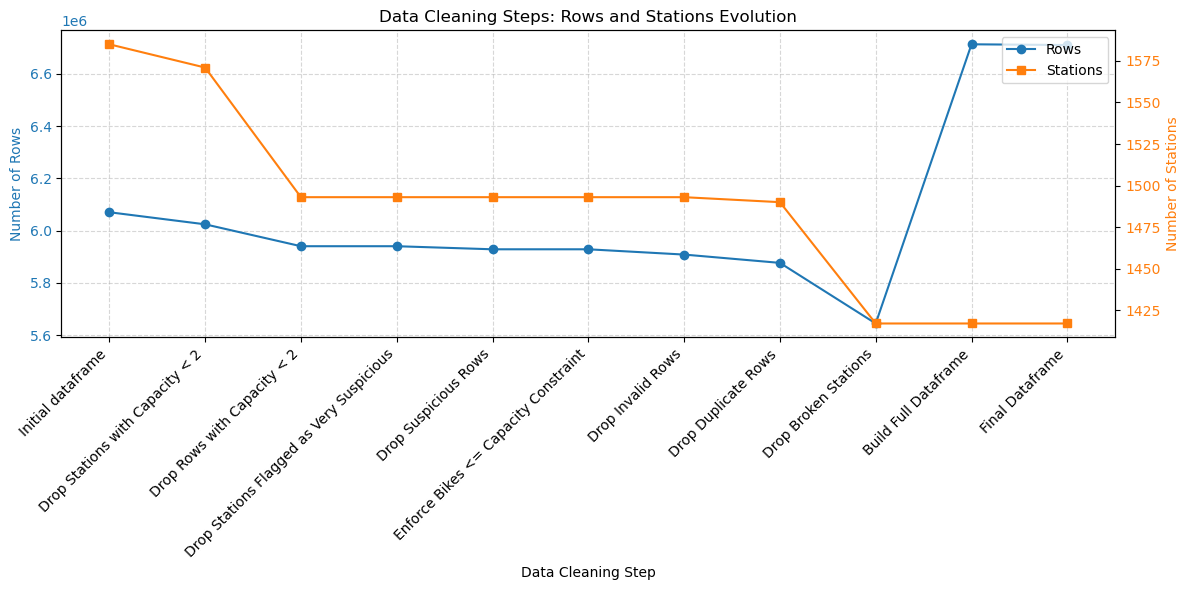

In [51]:
fig, ax1 = plt.subplots(figsize=(12,6))

ax1.plot(pip_stats["step"], pip_stats["rows"], color='tab:blue', marker='o', label="Rows")
ax1.set_xlabel("Data Cleaning Step")
ax1.set_ylabel("Number of Rows", color='tab:blue')
ax1.tick_params(axis='y', labelcolor='tab:blue')
ax1.set_xticks(range(len(pip_stats)))
ax1.set_xticklabels(pip_stats["step"], rotation=45, ha='right')

ax2 = ax1.twinx()
ax2.plot(pip_stats["step"], pip_stats["stations"], color='tab:orange', marker='s', label="Stations")
ax2.set_ylabel("Number of Stations", color='tab:orange')
ax2.tick_params(axis='y', labelcolor='tab:orange')

ax1.grid(True, which='both', linestyle='--', alpha=0.5)


plt.title("Data Cleaning Steps: Rows and Stations Evolution")


lines, labels = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines + lines2, labels + labels2, loc="upper right")

plt.tight_layout()

# Save plot
plt.savefig(f"{PIPELINE_PLOT_FOLDER}/pipeline_stats.png", dpi=300)
plt.show()
plt.close()

In [52]:
del pip_stats

# LOAD MODEL RESULTS

In [53]:
stats_new = pd.read_csv(MODEL_STATS_FOLDER / "all_stations_results_all_models.csv")
stats_old = pd.read_csv(MODEL_STATS_FOLDER / "all_stations_results_all_models_old.csv")

# CONFIG THEIR STATS

In [54]:
def add_config(df):
    df = df.copy()
    df["config"] = (
        df["is_lagged"].map({True: "Lag", False: "No Lag"})
        + " + "
        + df["has_behavior_and_weather"].map({
            True: "Weather",
            False: "No Weather"
        })
    )
    return df

In [55]:
stats_new = add_config(stats_new)
stats_old = add_config(stats_old)

# PLOT 1: R^2 BY MODEL AND CONFIG

In [56]:
for cluster in sorted(stats_new["cluster"].unique()):
    plt.figure(figsize=(12, 5))
    data = stats_new[stats_new["cluster"] == cluster]

    sns.boxplot(
        data=data,
        x="model",
        y="r2",
        hue="config",
        showfliers=False
    )

    plt.title(f"Cluster {cluster} - R^2 Distribution per Model and Configuration")
    plt.ylabel("R^2")
    plt.xlabel("Model")
    plt.legend(title="Configuration")
    plt.tight_layout()

    plt.savefig(
        MODEL_STATS_PLOT_FOLDER / f"cluster_{cluster}_r2_boxplot.png"
    )
    plt.close()

# PLOT 2: RMSE BY MODEL AND CONFIG

In [57]:
for cluster in sorted(stats_new["cluster"].unique()):
    plt.figure(figsize=(12, 5))
    data = stats_new[stats_new["cluster"] == cluster]

    sns.boxplot(
        data=data,
        x="model",
        y="rmse",
        hue="config",
        showfliers=False
    )

    plt.title(f"Cluster {cluster} - RMSE Distribution per Model and Configuration")
    plt.ylabel("RMSE (lower is better)")
    plt.xlabel("Model")
    plt.legend(title="Configuration")
    plt.tight_layout()

    plt.savefig(
        MODEL_STATS_PLOT_FOLDER / f"cluster_{cluster}_rmse_boxplot.png"
    )
    plt.close()


# PLOT 3: BEST CONFIG PER MODEL

In [58]:
best = (
    stats_new
    .sort_values("r2", ascending=False)
    .groupby(["cluster", "model"], as_index=False)
    .first()
)

for cluster in sorted(best["cluster"].unique()):
    plt.figure(figsize=(8, 4))
    data = best[best["cluster"] == cluster]

    sns.barplot(
        data=data,
        x="model",
        y="r2",
        hue="config",
        dodge=False
    )

    plt.title(f"Cluster {cluster} - Best Configuration per Model (R^2)")
    plt.ylabel("Best R^2")
    plt.xlabel("Model")
    plt.legend(title="Configuration")
    plt.tight_layout()

    plt.savefig(MODEL_STATS_PLOT_FOLDER / f"cluster_{cluster}_best_config_r2.png")
    plt.close()

# PLOT 4: OLD VS NEW

In [59]:
stats_old["version"] = "Old"
stats_new["version"] = "New"
df_compare = pd.concat([stats_old, stats_new])

summary = (
    df_compare
    .groupby(["cluster", "model", "version"], as_index=False)["r2"]
    .mean()
)

for cluster in sorted(summary["cluster"].unique()):
    plt.figure(figsize=(8, 4))
    data = summary[summary["cluster"] == cluster]

    sns.lineplot(
        data=data,
        x="version",
        y="r2",
        hue="model",
        marker="o"
    )

    plt.title(f"Cluster {cluster} - Old vs New Mean R^2")
    plt.ylabel("Mean R^2")
    plt.xlabel("")
    plt.tight_layout()

    plt.savefig(MODEL_STATS_PLOT_FOLDER / f"cluster_{cluster}_old_vs_new_r2.png")
    plt.close()

# PLOT 5: R^2 VIOLIN

In [60]:
for cluster in sorted(stats_new["cluster"].unique()):
    plt.figure(figsize=(12, 5))
    data = stats_new[stats_new["cluster"] == cluster]

    sns.violinplot(
        data=data,
        x="model",
        y="r2",
        hue="config",
        cut=0,
        inner="quartile",
        scale="width"
    )

    plt.title(f"Cluster {cluster} - R^2 Distribution (Violin)")
    plt.ylabel("R^2")
    plt.xlabel("Model")
    plt.legend(title="Configuration")
    plt.tight_layout()

    plt.savefig(
        MODEL_STATS_PLOT_FOLDER / f"cluster_{cluster}_r2_violin.png"
    )
    plt.close()


C:\Users\emirh\AppData\Local\Temp\ipykernel_166716\114653679.py:5: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  sns.violinplot(
C:\Users\emirh\AppData\Local\Temp\ipykernel_166716\114653679.py:5: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  sns.violinplot(


# PLOT 6: RMSE VIOLIN

In [61]:
for cluster in sorted(stats_new["cluster"].unique()):
    plt.figure(figsize=(12, 5))
    data = stats_new[stats_new["cluster"] == cluster]

    sns.violinplot(
        data=data,
        x="model",
        y="rmse",
        hue="config",
        cut=0,
        inner="quartile",
        scale="width"
    )

    plt.title(f"Cluster {cluster} - RMSE Distribution (Violin)")
    plt.ylabel("RMSE (lower is better)")
    plt.xlabel("Model")
    plt.legend(title="Configuration")
    plt.tight_layout()

    plt.savefig(
        MODEL_STATS_PLOT_FOLDER / f"cluster_{cluster}_rmse_violin.png"
    )
    plt.close()


C:\Users\emirh\AppData\Local\Temp\ipykernel_166716\2350042922.py:5: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  sns.violinplot(
C:\Users\emirh\AppData\Local\Temp\ipykernel_166716\2350042922.py:5: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  sns.violinplot(


# DEL

In [62]:
del stats_old
del stats_new

# PUT THE SPLIT DATA IN PLOTS

In [63]:
def plot_split_presence(station_id, df, save_path=None):
    df_s = df[df["station_code"] == station_id].copy()

    # Round timestamps
    df_s["timestamp"] = pd.to_datetime(df_s["timestamp"]).dt.round("15min")

    # Extract date and time
    df_s["date"] = df_s["timestamp"].dt.date
    df_s["time"] = df_s["timestamp"].dt.time

    # Encode split:
    # 0 -> train -> 1
    # 1 -> val   -> 2
    # 2 -> test  -> 3
    split_map = {0: 1, 1: 2, 2: 3}
    df_s["split_code"] = df_s["split"].map(split_map)

    # Aggregate duplicates
    df_s_agg = (
        df_s.groupby(["date", "time"])["split_code"]
            .max()
            .reset_index()
    )

    # Pivot
    heatmap_df = (
        df_s_agg.pivot(index="date", columns="time", values="split_code")
        .fillna(0)
    )

    # Custom colormap
    cmap = ListedColormap([
        "white",      # 0 = missing
        "saddlebrown",# 1 = training
        "green",      # 2 = validation
        "orange"      # 3 = test
    ])

    # Plot
    plt.figure(figsize=(18, max(6, len(heatmap_df) / 5)))
    plt.imshow(heatmap_df, aspect="auto", cmap=cmap, interpolation="none")

    plt.xlabel("Time of day")
    plt.ylabel("Date")
    plt.title(f"Station {station_id} - Train / Val / Test presence")

    # Legend (manual, because imshow)
    legend_elements = [
        Patch(facecolor="saddlebrown", label="Train"),
        Patch(facecolor="green", label="Validation"),
        Patch(facecolor="orange", label="Test"),
        Patch(facecolor="white", edgecolor="black", label="Missing"),
    ]
    plt.legend(handles=legend_elements, loc="upper right")

    plt.tight_layout()

    if save_path:
        plt.savefig(save_path)
        plt.close()
    else:
        plt.show()
        plt.close()

# PLOT THEM

C:\Users\emirh\AppData\Local\Temp\ipykernel_166716\704919084.py:41: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  plt.imshow(heatmap_df, aspect="auto", cmap=cmap, interpolation="none")
C:\Users\emirh\AppData\Local\Temp\ipykernel_166716\704919084.py:41: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  plt.imshow(heatmap_df, aspect="auto", cmap=cmap, interpolation="none")
C:\Users\emirh\AppData\Local\Temp\ipykernel_166716\704919084.py:41: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  plt.imshow(heatmap_df, aspect="auto", cmap=cmap, interpolation="none")
C:\Users\emirh\AppData\Local\Temp\ipykernel_166716\704919084.py:41: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  plt.imshow(heatmap_df, aspect="auto", cmap=

KeyboardInterrupt: 

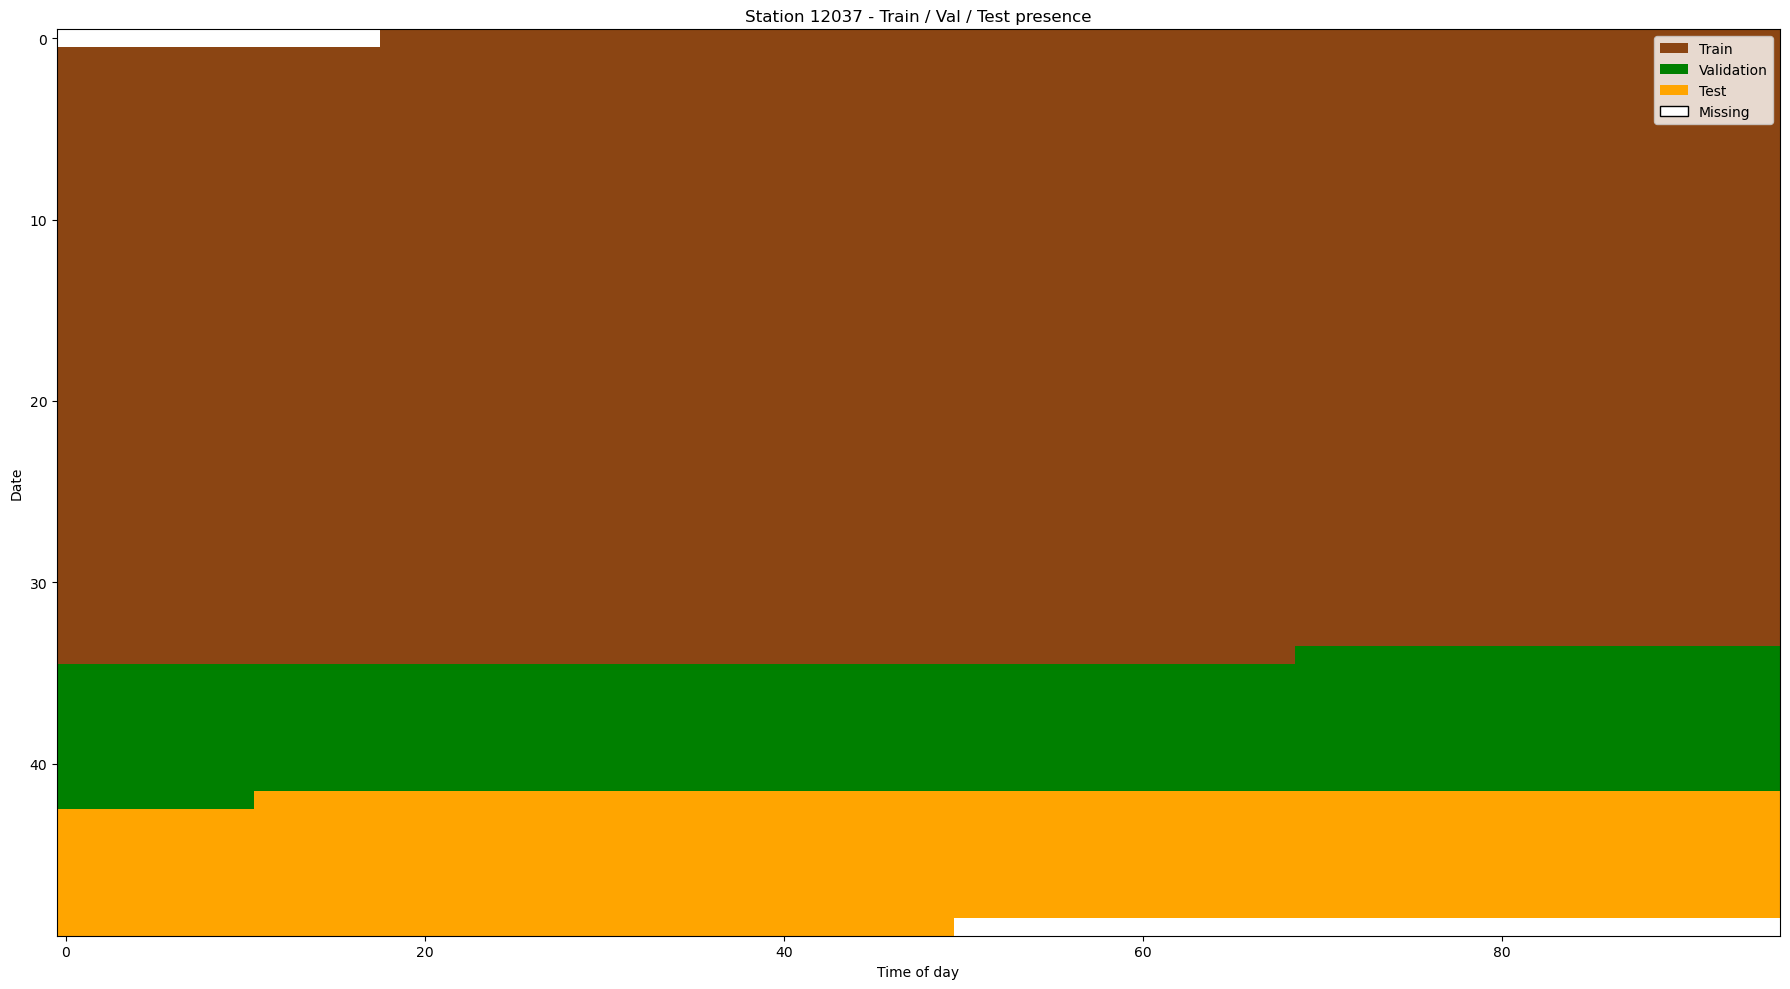

In [64]:
for station_id in df["station_code"].unique():
    plot_split_presence(
        station_id,
        df,
        save_path=f"{STATION_SPLIT_WELNESS_FOLDER}/split_presence_station_{station_id}.png"
    )

# PUT THE MISSING DATA IN PLOTS

In [ ]:
def plot_missing_data(station_id, df, save_path=None):
    df_s = df[df["station_code"] == station_id].copy()

    # Snap timestamps to nearest 15min to reduce misalignment issues
    df_s["timestamp"] = pd.to_datetime(df_s["timestamp"]).dt.round("15min")

    # Extract date and time
    df_s["date"] = df_s["timestamp"].dt.date
    df_s["time"] = df_s["timestamp"].dt.time

    # Mark presence
    df_s["present"] = 1

    # Aggregate duplicates
    df_s_agg = df_s.groupby(["date", "time"])["present"].max().reset_index()

    # Pivot
    heatmap_df = df_s_agg.pivot(index="date", columns="time", values="present").fillna(0)

    # Convert time columns to numeric hours for X-axis
    x_labels = [pd.Timestamp.combine(pd.Timestamp.today(), t).hour + pd.Timestamp.combine(pd.Timestamp.today(), t).minute/60 for t in heatmap_df.columns]

    # Plot
    plt.figure(figsize=(18, max(6, len(heatmap_df)/5)))
    plt.imshow(heatmap_df, aspect="auto", cmap="Greens", interpolation="none")
    plt.xticks(ticks=np.linspace(0, len(x_labels)-1, 12), 
               labels=[f"{int(x)}:00" for x in np.linspace(0, 24, 12)], rotation=45)
    plt.yticks(range(len(heatmap_df.index)), [str(d) for d in heatmap_df.index])
    plt.xlabel("Time of day")
    plt.ylabel("Date")
    plt.title(f"Station {station_id} - Missing data pattern")
    plt.colorbar(label="Presence (1=present, 0=missing)")
    plt.tight_layout()

    if save_path:
        plt.savefig(save_path)
        plt.close()
    else:
        plt.show()
        plt.close()

# SAVE IT

KeyboardInterrupt: 

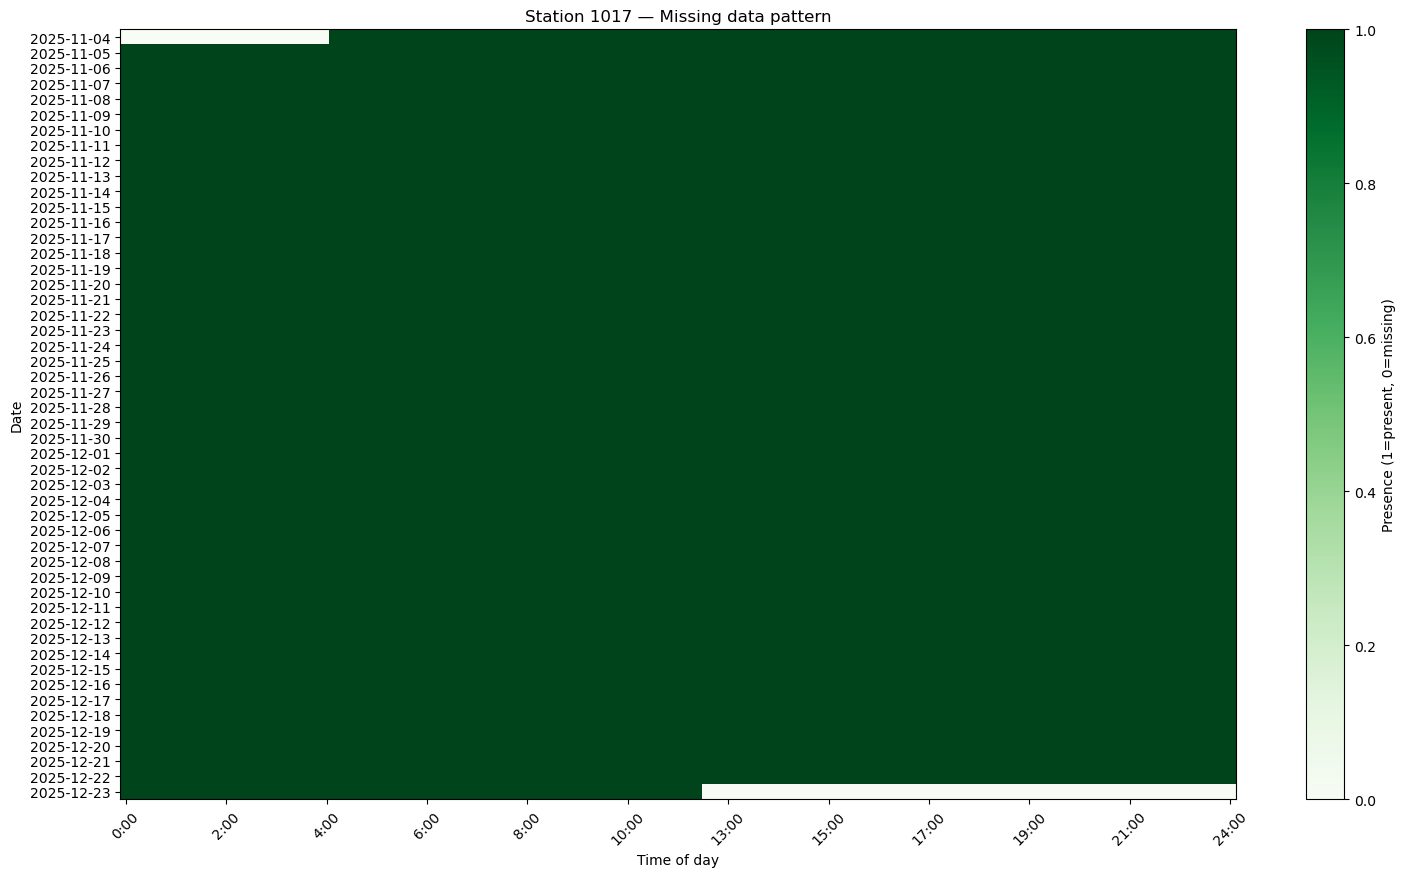

In [ ]:
for station_id in df["station_code"].unique():
    plot_missing_data(station_id, df, save_path=f"{PLOT_FOLDER}/station_{station_id}.png")

print("All station plots generated.")